# 7BDNI013C — Data Mining and Machine Learning
## Mortgage Loan Application Outcome Prediction
**Dataset:** HMDA Public Loan-Level Dataset — Pennsylvania, Actions 1-2-3, Loan Purpose 1  
**Source:** Consumer Financial Protection Bureau (CFPB)  
**Target:** `action_taken` — 0 = Application Denied, 1 = Approved but Not Accepted, 2 = Loan Originated


## 0. Imports & Global Config

In [ ]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42

## 1. Data Loading

The dataset is loaded from the raw HMDA CSV file. A copy is made immediately so the original is never modified.  
`low_memory=False` is required because several columns contain mixed types (numeric codes and exempt markers) that pandas cannot infer from the first rows alone.


In [43]:
raw = pd.read_csv('../actions_taken_1-2-3_loan_purposes_1_state_PA.csv', low_memory=False)
copy = raw.copy()
print(f"Dataset shape: {copy.shape[0]:,} rows × {copy.shape[1]} columns")

Dataset shape: 139,301 rows × 99 columns


## 2. Initial Data Audit

`auditor()` inspects every column for data type, missing value count, and unique value count.  
This gives a structural overview of the raw dataset before any cleaning is applied.


In [ ]:
from modules.audit import auditor

audit_raw = auditor(copy)
audit_raw

## 3. Data Cleaning

Cleaning is applied in four sequential steps:

1. **`one_value()`** — drops columns with only a single unique value (zero information content)  
2. **`cardinals()`** — drops `lei`, a unique legal entity identifier per institution (effectively a row ID, cannot generalise)  
3. **`leaker()`** — drops columns that would cause data leakage: `purchaser_type` (known only after loan sale) and `denial_reason-*` (directly encodes the target outcome)  
4. **`high_missing()`** — drops columns where ≥50% of values are missing (imputing beyond this threshold manufactures more data than it recovers)  
5. **`transformer()`** — converts columns stored as strings to their correct numeric types (HMDA stores exempt/NA codes mixed into numeric fields, causing string dtype)


In [45]:
from modules.cleaner import one_value, cardinals, leaker, high_missing, transformer

shape_before = copy.shape
copy = one_value(copy)
copy = cardinals(copy)
copy = leaker(copy)
copy = high_missing(copy)
copy = transformer(copy)
shape_after = copy.shape

print(f"Before cleaning: {shape_before[0]:,} rows × {shape_before[1]} columns")
print(f"After cleaning:  {shape_after[0]:,} rows × {shape_after[1]} columns")
print(f"Columns removed: {shape_before[1] - shape_after[1]}")

Before cleaning: 139,301 rows × 99 columns
After cleaning:  139,301 rows × 63 columns
Columns removed: 36


## 4. Feature Engineering & Mapping

`mapper()` transforms raw HMDA integer codes into human-readable string labels and engineers new features:

- All integer-coded columns (loan type, race, sex, AUS system, etc.) are mapped to their HMDA codebook descriptions. This ensures the model receives meaningful categorical signals rather than arbitrary integers.
- `total_units` is converted to a binary `is_single_family` flag — the most important distinction for mortgage risk is single-family vs. multi-unit, not the exact unit count.
- `applicant_age` and `co-applicant_age` are ordinally encoded (1–7 for age bands). Code `8888` (Not Applicable) is captured as a separate binary flag. Code `9999` (No Co-applicant) is captured as `no_coapplicant` binary flag — preserving information that would otherwise be lost.
- `hoepa_status` was mapped in an earlier version but was removed because it was not present in the model's feature list and was silently dropped by the preprocessor.

**Note:** `action_taken` is mapped here for EDA readability. It is re-encoded numerically (0/1/2) in the modelling section.


In [46]:
from modules.mapper import mapper

copy = mapper(copy)
print(f"Shape after mapping: {copy.shape[0]:,} rows × {copy.shape[1]} columns")
copy.head(3)

Shape after mapping: 139,301 rows × 66 columns


,derived_msa-md,county_code,census_tract,conforming_loan_limit,derived_loan_product_type,derived_dwelling_category,derived_ethnicity,derived_race,derived_sex,action_taken,preapproval,loan_type,lien_status,reverse_mortgage,open-end_line_of_credit,business_or_commercial_purpose,loan_amount,loan_to_value_ratio,interest_rate,rate_spread,hoepa_status,total_loan_costs,origination_charges,loan_term,negative_amortization,interest_only_payment,balloon_payment,other_nonamortizing_features,property_value,construction_method,occupancy_type,manufactured_home_secured_property_type,manufactured_home_land_property_interest,income,debt_to_income_ratio,applicant_credit_score_type,co-applicant_credit_score_type,applicant_ethnicity-1,co-applicant_ethnicity-1,applicant_ethnicity_observed,co-applicant_ethnicity_observed,applicant_race-1,co-applicant_race-1,applicant_race_observed,co-applicant_race_observed,applicant_sex,co-applicant_sex,applicant_sex_observed,co-applicant_sex_observed,applicant_age_above_62,submission_of_application,initially_payable_to_institution,aus-1,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units,is_single_family,applicant_age_ord,applicant_age_not_applicable,coapplicant_age_ord,coapplicant_age_not_applicable,no_coapplicant
0,42540,42069.0,4.206910e+10,Conforming,FHA:First Lien,1,Not Hispanic or Latino,Asian,Joint,Loan_originated,Not_requested,FHA,First_lien,No,No,No,95000.0,62.094,3.250,NaN,2,3456.19,1800.00,304.0,No,No,No,No,155000.0,Site-built,Principal_residence,Not_applicable,Not_applicable,59.0,NaN,Equifax_Beacon_5.0,Not_applicable,Not_Hispanic_or_Latino,Not_Hispanic_or_Latino,Not_collected_on_visual_observation_or_surname,Not_collected_on_visual_observation_or_surname,Asian,Asian,Not_collected_on_visual_observation_or_surname,Not_collected_on_visual_observation_or_surname,Male,Female,Not_collected_on_visual_observation_or_surname,Not_collected_on_visual_observation_or_surname,No,Submitted_directly_to_institution,Initially_payable_to_your_institution,Internal_Proprietary_AUS,2039,45.12,83000,108,443,1062,0,1,5,0,5,0,0
1,21500,42049.0,4.204901e+10,Conforming,VA:First Lien,1,Not Hispanic or Latino,White,Male,Loan_originated,Not_requested,VA,First_lien,No,No,No,165000.0,100.000,3.625,NaN,3,4027.64,709.00,328.0,No,No,No,No,165000.0,Site-built,Investment_property,Not_applicable,Not_applicable,221.0,NaN,Equifax_Beacon_5.0,Not_applicable,Not_Hispanic_or_Latino,Not_Hispanic_or_Latino,Not_collected_on_visual_observation_or_surname,Not_collected_on_visual_observation_or_surname,White,White,Not_collected_on_visual_observation_or_surname,Not_collected_on_visual_observation_or_surname,Male,Male,Not_collected_on_visual_observation_or_surname,Not_collected_on_visual_observation_or_surname,No,Submitted_directly_to_institution,Initially_payable_to_your_institution,Desktop_Underwriter_(DU),3531,8.95,80500,91,1000,1433,64,1,2,0,2,0,0
2,37964,42101.0,4.210104e+10,Conforming,FHA:First Lien,1,Not Hispanic or Latino,Black or African American,Female,Loan_originated,Not_requested,FHA,First_lien,No,No,No,315000.0,96.500,6.625,0.56,2,11999.43,1749.11,360.0,No,No,No,No,325000.0,Site-built,Principal_residence,Not_applicable,Not_applicable,102.0,NaN,Equifax_Beacon_5.0,No_co-applicant,Not_Hispanic_or_Latino,No_co-applicant,Not_collected_on_visual_observation_or_surname,No_co-applicant,Black_or_African_American,No_co-applicant,Not_collected_on_visual_observation_or_surname,No_co-applicant,Female,No_co-applicant,Not_collected_on_visual_observation_or_surname,No_co-applicant,No,Not_submitted_directly_to_institution,Initially_payable_to_your_institution,GUS,6695,16.88,84300,148,2079,2424,56,1,4,0,0,0,1


## 5. Post-Cleaning Summary

`summarizer()` provides a final structural overview after all cleaning and mapping steps.  
This confirms that data types are correct, missing values are at acceptable levels, and no unexpected columns remain.


In [47]:
from modules.audit import summarizer

summary = summarizer(copy)
summary

,Data Type,Non-Null Count,Missing Count,Unique Values,Sample Values
derived_msa-md,int64,139301,0,18,[42540]
county_code,float64,138433,868,67,[42069.0]
census_tract,float64,137897,1404,3376,[42069100400.0]
conforming_loan_limit,string,139301,0,4,[Conforming]
derived_loan_product_type,str,139301,0,7,[FHA:First Lien]
derived_dwelling_category,int64,139301,0,4,[1]
derived_ethnicity,str,139301,0,5,[Not Hispanic or Latino]
derived_race,str,139301,0,9,[Asian]
derived_sex,str,139301,0,4,[Joint]
action_taken,string,139301,0,3,[Loan_originated]


## 6. Exploratory Data Analysis

The EDA focuses on understanding the target distribution, key numeric feature relationships with outcomes, and potential fairness signals in the data. Each visualisation is chosen to inform a specific preprocessing or modelling decision — not for completeness.

**Key findings to note:**
- The dataset is severely imbalanced (~86% Loan Originated). This directly motivates the choice of macro F1 as the evaluation metric and the use of `class_weight` in tree-based models.
- Denied applications cluster at higher DTI ratios and lower incomes — the model must learn these boundaries.
- Denial rates vary by race and neighbourhood minority population percentage — a fairness consideration noted in the business recommendation.
- Interest rate and rate spread show strong separation by outcome — these are post-decision leakers and have been removed before modelling.


In [48]:
from modules.EDA import (plot_target_distribution, plot_boxplots_numeric,
                         plot_ltv_histogram, plot_scatter_income_loan,
                         plot_loantype_vs_outcome, plot_denial_by_race,
                         plot_preapproval_vs_outcome, plot_neighborhood_income,
                         plot_minority_tract_denial, plot_correlation_heatmap)

### 6.1 Target Class Distribution

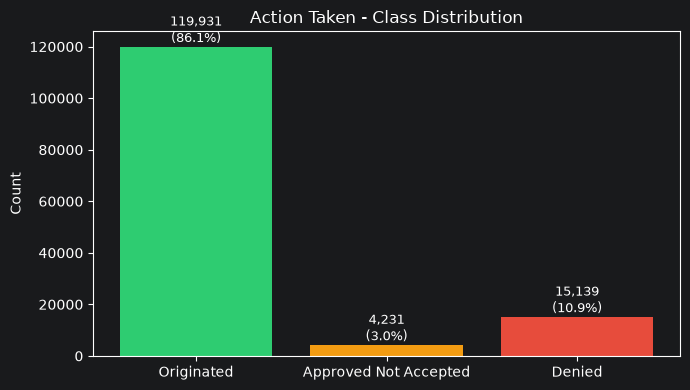

In [49]:
plot_target_distribution(copy)

### 6.2 Numeric Features by Outcome

Income and loan amount are clipped to realistic ranges (0–500k and 0–1M respectively) to remove data entry errors and extreme outliers that would compress the box plots. The DTI panel uses a bar chart because DTI in this dataset is a bucketed ordinal variable, not a true continuous one.


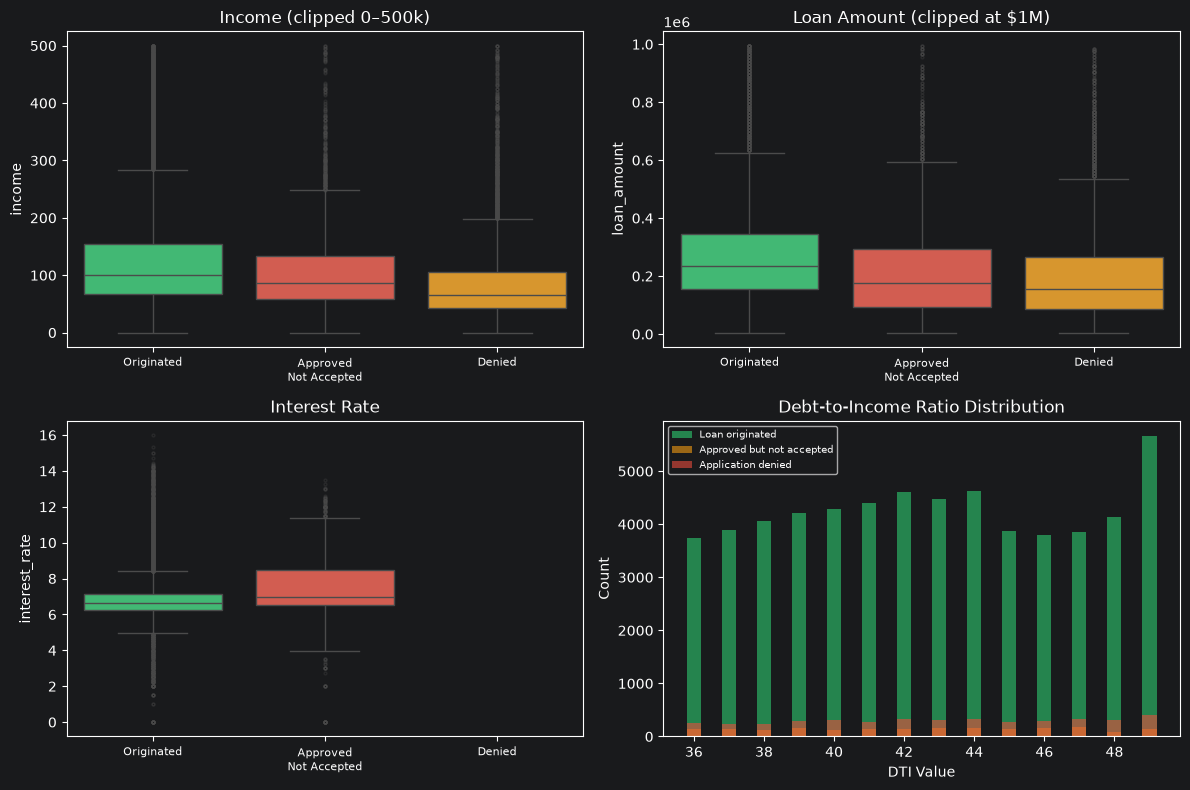

In [50]:
plot_boxplots_numeric(copy)

### 6.3 Loan-to-Value Ratio Distribution

Values above 105% are excluded as dirty data (LTV cannot physically exceed 100% for standard loans). The 80% and 100% reference lines mark the conventional PMI threshold and the negative equity boundary.


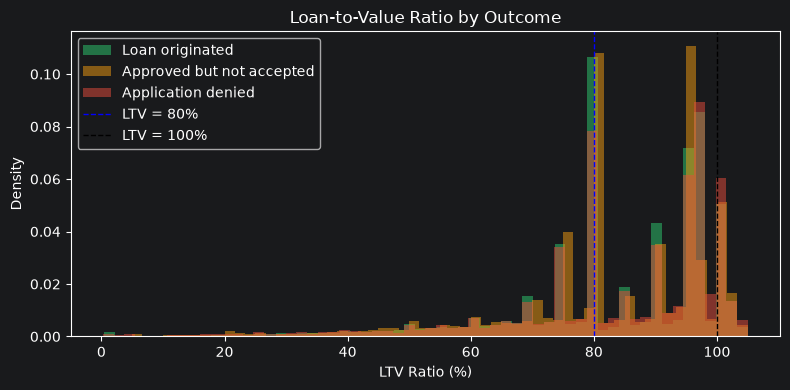

In [51]:
plot_ltv_histogram(copy)

### 6.4 Income vs Loan Amount by Outcome

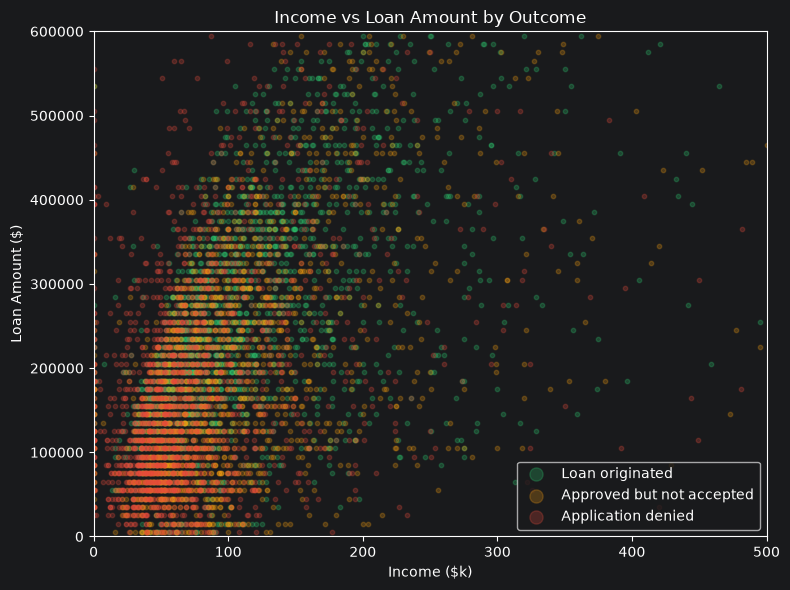

In [52]:
plot_scatter_income_loan(copy)

### 6.5 Loan Type vs Outcome Rate

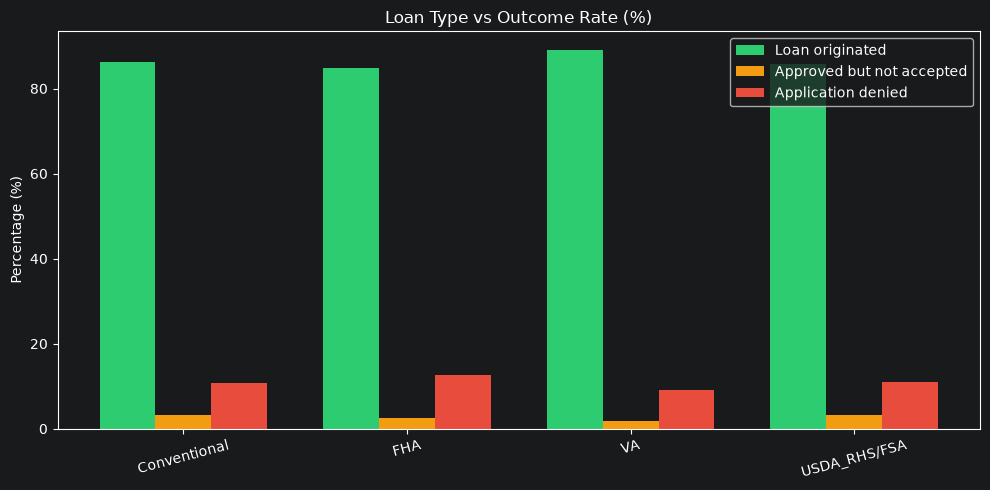

In [53]:
plot_loantype_vs_outcome(copy)

### 6.6 Denial Rate by Race

Only racial groups with 100 or more applications are shown to avoid unstable rates from very small samples.  
This chart is included because fairness of lending decisions is a core regulatory concern in HMDA data.


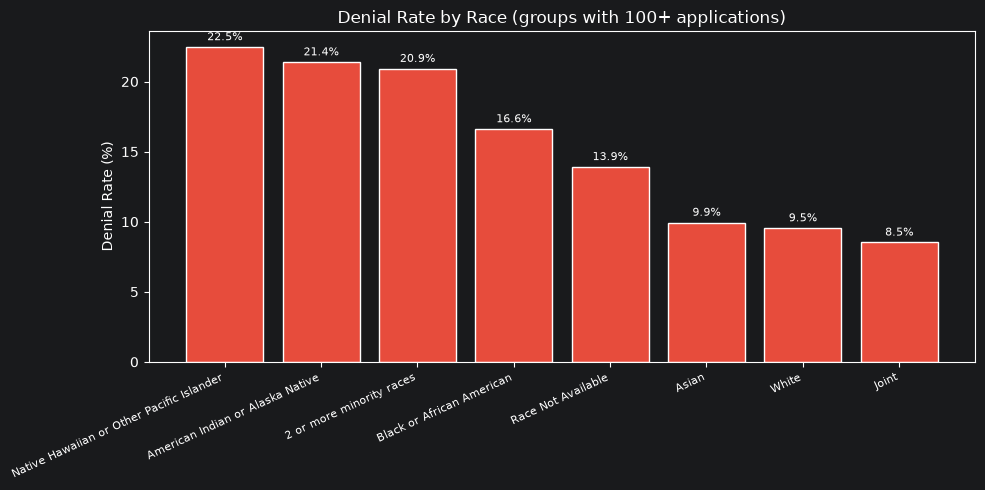

In [54]:
plot_denial_by_race(copy)

### 6.7 Preapproval Status vs Outcome

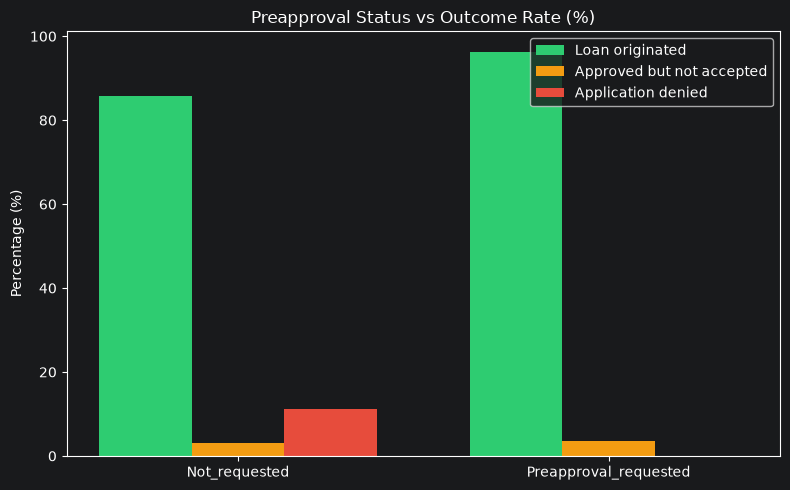

In [55]:
plot_preapproval_vs_outcome(copy)

### 6.8 Neighbourhood Median Income vs Outcome

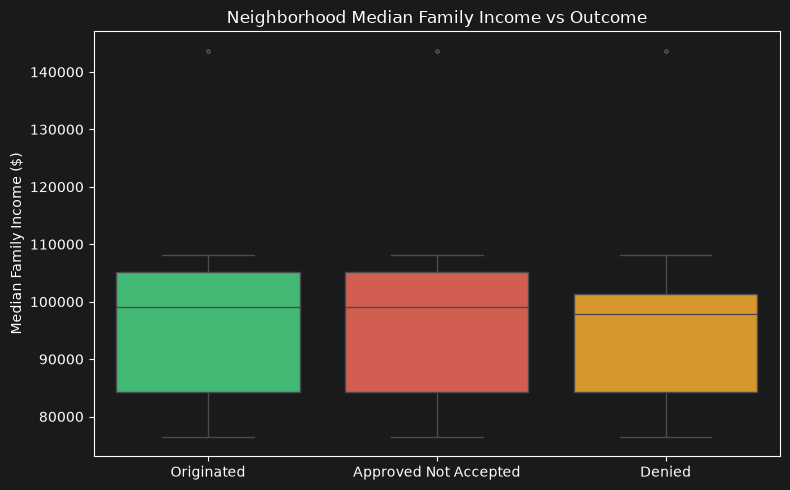

In [56]:
plot_neighborhood_income(copy)

### 6.9 Denial Rate vs Tract Minority Population %

This chart bins census tracts by their minority population percentage and shows how denial rates increase with minority concentration — a key fairness signal in HMDA analysis.


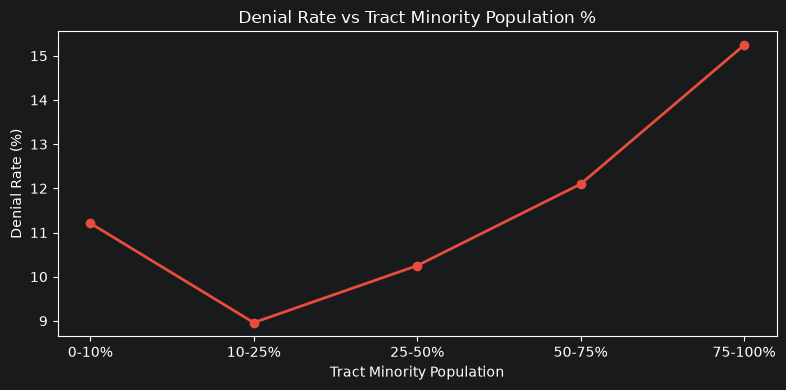

In [57]:
plot_minority_tract_denial(copy)

### 6.10 Correlation Matrix

Rate spread and property value are clipped before computing correlations to prevent extreme outliers from distorting the correlation coefficients. Income and loan amount are also clipped to the same ranges used in the boxplots.


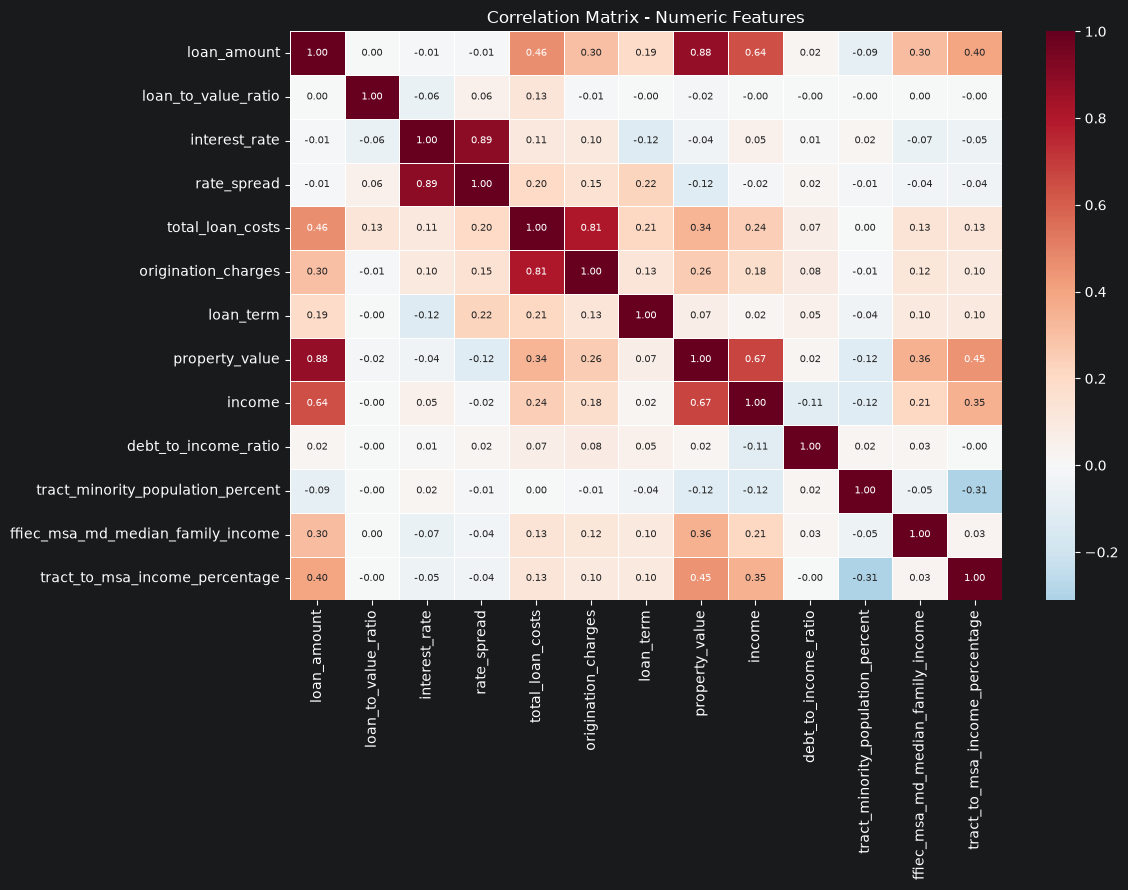

In [58]:
plot_correlation_heatmap(copy)

## 7. Target Encoding & Train / Validation / Test Split

`action_taken` is re-encoded numerically for modelling:
- `Loan_originated` → 2 (majority class, ~86%)
- `Approved_but_not_accepted` → 1 (smallest minority)
- `Application_denied` → 0

The data is split into three stratified partitions. Stratification ensures each split preserves the class distribution. The test set (20%) is held out completely and is not touched until the winning model has been selected from validation results.

```
Full data (139,301 rows)
│
├── trainval 80% (111,440 rows)
│   ├── X_train 80% of trainval (~89,152 rows)  ← GridSearchCV fits here
│   └── X_valid 20% of trainval (~22,288 rows)  ← post-tuning model comparison
│
└── X_test 20% (27,861 rows)  ← untouched until winner is chosen
```


In [59]:

action_map = {
    'Loan_originated':           2,
    'Approved_but_not_accepted': 1,
    'Application_denied':        0
}
copy['action_taken'] = copy['action_taken'].map(action_map)

X = copy.drop(columns=['action_taken'])
y = copy['action_taken']

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_trainval, y_trainval, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_trainval)

print(f"X_train : {X_train.shape[0]} rows")
print(f"X_valid : {X_valid.shape[0]} rows")
print(f"X_test  : {X_test.shape[0]} rows")
print(f"\nClass distribution in y_train:\n{y_train.value_counts(normalize=True).round(3)}")

X_train : 89152 rows
X_valid : 22288 rows
X_test  : 27861 rows

Class distribution in y_train:
action_taken
2    0.861
0    0.109
1    0.030
Name: proportion, dtype: float64


## 8. Modelling

All modelling functions are imported from `modeler.py`. The file contains:
- `preprocessor_scaled` and `preprocessor_not_scaled` — sklearn Pipelines that apply imputation and optional scaling. Both are fitted only on training data via GridSearchCV, preventing leakage.
- `baseline_model()` — DummyClassifier (most_frequent strategy)
- `tune_log_reg()`, `tune_dec_tree()`, `tune_r_forest()`, `tune_xgboost()` — each runs GridSearchCV on training data, evaluates the best estimator on validation, and plots feature importances
- `plot_confusion_matrix()` — plots a confusion matrix for any fitted model
- `evaluate_winner_on_test()` — finds the best threshold on validation, then evaluates the winner on the test set exactly once

**Metric choice:** Macro F1 is used as the primary selection metric. Accuracy is dominated by the majority class (~86%) and is misleading for model selection. Macro F1 weights all three classes equally, penalising models that ignore minority classes — which is both statistically correct and aligned with the regulatory intent of HMDA data.


In [ ]:
from modules.modeler import (
    baseline_model,
    tune_log_reg,
    tune_dec_tree,
    tune_r_forest,
    tune_xgboost,
    plot_confusion_matrix,
    evaluate_winner_on_test
)

### 8.1 Baseline Model

A `DummyClassifier(strategy='most_frequent')` predicts the majority class (Loan Originated) for every observation. With ~86% class 2, it achieves ~86% accuracy by never predicting a minority class. Any real model must beat this in macro F1 to demonstrate genuine learning.


In [ ]:
baseline_model(X_train, y_train, X_valid, y_valid)

### 8.2 Logistic Regression (Tuned)

Logistic Regression is included as the simplest interpretable classifier above the dummy baseline. It is appropriate for large tabular datasets and provides coefficient-based interpretability.

**Known limitation:** Logistic Regression relies on a linear decision boundary. With severe class imbalance on complex, non-linear data (financial interactions between income, DTI, loan type, race), it hits a hard performance ceiling on minority classes. `class_weight='balanced'` was tested and found to cause a surge of false positives for this linear model — a finding that justifies the inclusion of tree-based models.

**Grid:** C ∈ {0.01, 1, 100} × class_weight ∈ {None, balanced} = 6 combos × 3 CV = 18 fits


In [ ]:
log_model, log_params, log_cv, log_eval = tune_log_reg(X_train, y_train, X_valid, y_valid)
plot_confusion_matrix(log_model, X_valid, y_valid, 'Logistic Regression (Tuned)')

### 8.3 Decision Tree (Tuned)

A single Decision Tree is included to illustrate how the base learner behind ensemble methods behaves in isolation. It is interpretable and fast, but prone to overfitting and instability.

**Known limitation:** When `class_weight='balanced'` is applied, the tree alters split thresholds aggressively to capture rare cases, introducing a large wave of false positives and degrading overall accuracy. This contrast with Random Forest demonstrates why ensembling is necessary.

**Grid:** max_depth ∈ {5, 10, 20} × min_samples_leaf ∈ {1, 5} × criterion ∈ {gini, entropy} × class_weight ∈ {balanced} = 12 combos × 3 CV = 36 fits


In [ ]:
dt_model, dt_params, dt_cv, dt_eval = tune_dec_tree(X_train, y_train, X_valid, y_valid)
plot_confusion_matrix(dt_model, X_valid, y_valid, 'Decision Tree (Tuned)')

### 8.4 Random Forest (Tuned)

Random Forest is the primary ensemble candidate. It handles mixed feature types, is robust to outliers, and can capture non-linear interactions between features (e.g. income × loan type × race) that Logistic Regression cannot.

`class_weight='balanced'` improved Random Forest performance on minority classes where it did not help Logistic Regression — tree-based models create branching, non-linear rules that can isolate minority patterns without generating a massive wave of false positives.

`class_weight='balanced_subsample'` recomputes weights per bootstrap sample and was also searched.

**Grid:** n_estimators ∈ {100, 300} × max_depth ∈ {10, None} × class_weight ∈ {balanced, balanced_subsample} × max_features ∈ {sqrt} = 8 combos × 3 CV = 24 fits


In [ ]:
rf_model, rf_params, rf_cv, rf_eval = tune_r_forest(X_train, y_train, X_valid, y_valid)
plot_confusion_matrix(rf_model, X_valid, y_valid, 'Random Forest (Tuned)')

### 8.5 XGBoost (Tuned)

XGBoost is the strongest candidate. It sequentially corrects errors from previous trees, handles structured tabular data well, and typically outperforms Random Forest by focusing on the hardest-to-classify examples.

**Grid:** n_estimators ∈ {100, 300} × max_depth ∈ {3, 5} × learning_rate ∈ {0.05, 0.1, 0.2} = 12 combos × 3 CV = 36 fits


In [ ]:
xgb_model, xgb_params, xgb_cv, xgb_eval = tune_xgboost(X_train, y_train, X_valid, y_valid)
plot_confusion_matrix(xgb_model, X_valid, y_valid, 'XGBoost (Tuned)')

## 9. Model Comparison on Validation Set

All four tuned models are compared on the same validation set using the same metrics. The winner is selected based on macro F1 — the primary metric. The test set is not consulted at this stage.


In [ ]:
comparison = pd.DataFrame([log_eval, dt_eval, rf_eval, xgb_eval])
comparison[['model', 'macro_f1', 'roc_auc', 'balanced_accuracy']].sort_values(
    by='macro_f1', ascending=False).reset_index(drop=True)

## 10. Final Test Evaluation

The winning model (replace `rf_model` / `'Random Forest'` with the actual winner from the comparison table above) is evaluated on the test set **exactly once**.

Before touching the test set, the optimal classification threshold for the minority class (class 1 — Approved but Not Accepted) is found using the validation set. This threshold is then applied to the test set predictions. The test set is never used to select the threshold.


In [ ]:
# Replace rf_model and 'Random Forest' with your actual winner after checking the comparison table above
test_results = evaluate_winner_on_test(
    winner_model = rf_model,        # <-- replace with winner
    winner_name  = 'Random Forest', # <-- replace with winner name
    X_valid      = X_valid,
    y_valid      = y_valid,
    X_test       = X_test,
    y_test       = y_test,
    target_class = 1                # 0=Denied, 1=Approved-not-accepted, 2=Originated
)

## 11. Best Hyperparameters Summary

A summary of the best parameter combination found by GridSearchCV for each model.


In [ ]:
params_summary = pd.DataFrame([
    {'Model': 'Logistic Regression', **log_params},
    {'Model': 'Decision Tree',       **dt_params},
    {'Model': 'Random Forest',       **rf_params},
    {'Model': 'XGBoost',             **xgb_params},
])
params_summary